In [19]:

# =====================================================================
# EXPERIMENT 03 — FOG DENSITY EVALUATION
# Cityscapes -> Foggy Cityscapes
#
# Source-Only vs Adaptive Teacher (5000 iterations)
#
# Run in a FRESH Jupyter kernel.
# =====================================================================

import os
import sys
import re
import json
import copy
import gc
import importlib
from pathlib import Path

import torch
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------
# 1. ENVIRONMENT
# ---------------------------------------------------------------------

ROOT = Path("/workspace")
BASE = ROOT / "experiments/cityscapes_to_foggy"
DATA_ROOT = ROOT / "datasets"

REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
COMPAT = BASE / "source_only/pilot_1000_v1/python_compat"

SOURCE_DIR = BASE / "source_only/continuation_5000_v1"
TEACHER_DIR = BASE / "adaptive_teacher/pilot_5000_warmstart_v2"

SOURCE_CHECKPOINT = SOURCE_DIR / "model_final.pth"
TEACHER_CHECKPOINT = TEACHER_DIR / "model_final.pth"

OUTPUT_DIR = BASE / "fog_density_evaluation/v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["DETECTRON2_DATASETS"] = str(DATA_ROOT)

for folder in [str(COMPAT), str(REPO)]:
    if folder not in sys.path:
        sys.path.insert(0, folder)

assert SOURCE_CHECKPOINT.is_file(), SOURCE_CHECKPOINT
assert TEACHER_CHECKPOINT.is_file(), TEACHER_CHECKPOINT
assert torch.cuda.is_available(), "CUDA GPU not available."

print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUTPUT_DIR)

# ---------------------------------------------------------------------
# 2. DETECTRON2 AND CUSTOM MODEL REGISTRATION
# ---------------------------------------------------------------------

from detectron2.config import get_cfg
from detectron2.data import (
    DatasetCatalog,
    MetadataCatalog,
    build_detection_test_loader,
)
from detectron2.data.datasets import register_coco_instances
from detectron2.data.datasets.cityscapes import load_cityscapes_instances
from detectron2.data.datasets.builtin import register_all_cityscapes
from detectron2.modeling import build_model
from detectron2.modeling.backbone import BACKBONE_REGISTRY
from detectron2.modeling.meta_arch.build import META_ARCH_REGISTRY
from detectron2.modeling.proposal_generator.build import (
    PROPOSAL_GENERATOR_REGISTRY,
)
from detectron2.evaluation import COCOEvaluator, inference_on_dataset

from adapteacher.config import add_ateacher_config

# Register model components through their normal package imports.
# Import once only. Never reload these modules.
import adapteacher.modeling
import prod_lib.modeling

# Some repository versions do not expose all registrations through
# __init__.py. Import missing components only after checking registry.

def find_and_register(name, registry):
    if name in registry._obj_map:
        return

    candidates = []

    for file in REPO.rglob("*.py"):
        try:
            content = file.read_text(errors="replace")
        except OSError:
            continue

        if re.search(
            rf"\b(?:def|class)\s+{re.escape(name)}\b",
            content
        ):
            candidates.append(file)

    if not candidates:
        raise RuntimeError(
            f"Implementation not found for {name}"
        )

    for file in candidates:
        if name in registry._obj_map:
            break

        module = ".".join(
            file.relative_to(REPO).with_suffix("").parts
        )

        if module not in sys.modules:
            importlib.import_module(module)

    if name not in registry._obj_map:
        raise RuntimeError(
            f"Could not register {name}. "
            f"Candidate modules: {candidates}"
        )


# ---------------------------------------------------------------------
# 3. CONFIGURATIONS
# ---------------------------------------------------------------------

TEACHER_CONFIG = TEACHER_DIR / "adaptive_teacher_5000.yaml"

assert TEACHER_CONFIG.is_file(), TEACHER_CONFIG

# Prefer the source-only config saved with the 5000-iteration run.
source_candidates = [
    SOURCE_DIR / "config.yaml",
    SOURCE_DIR / "source_only_5000.yaml",
    SOURCE_DIR / "source_only.yaml",
]

SOURCE_CONFIG = next(
    (p for p in source_candidates if p.is_file()),
    None
)

if SOURCE_CONFIG is None:
    yaml_files = sorted(SOURCE_DIR.rglob("*.yaml"))

    if len(yaml_files) == 1:
        SOURCE_CONFIG = yaml_files[0]

if SOURCE_CONFIG is None:
    raise FileNotFoundError(
        "Source-Only 5000-iteration YAML was not found. "
        "Please locate the original training config; "
        "do not substitute another config."
    )


def load_config(path):
    cfg = get_cfg()
    add_ateacher_config(cfg)
    cfg.merge_from_file(str(path))

    cfg.defrost()
    cfg.MODEL.DEVICE = "cuda"
    cfg.DATALOADER.NUM_WORKERS = 0
    cfg.freeze()

    return cfg


source_cfg = load_config(SOURCE_CONFIG)
teacher_cfg = load_config(TEACHER_CONFIG)

print("\nSource config:", SOURCE_CONFIG)
print("Teacher config:", TEACHER_CONFIG)

# Register only components required by the two configurations.
for cfg in [source_cfg, teacher_cfg]:
    find_and_register(
        cfg.MODEL.META_ARCHITECTURE,
        META_ARCH_REGISTRY
    )
    find_and_register(
        cfg.MODEL.BACKBONE.NAME,
        BACKBONE_REGISTRY
    )
    find_and_register(
        cfg.MODEL.PROPOSAL_GENERATOR.NAME,
        PROPOSAL_GENERATOR_REGISTRY
    )

print("\nModel components registered.")

# ---------------------------------------------------------------------
# 4. DATASET REGISTRATION
# ---------------------------------------------------------------------

FOG_LEVELS = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

CLASSES = [
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

SOURCE_DATASET = "cityscapes_fine_instance_seg_val"

if SOURCE_DATASET not in DatasetCatalog.list():
    register_all_cityscapes(str(DATA_ROOT))

source_records = DatasetCatalog.get(SOURCE_DATASET)

assert len(source_records) == 500, (
    f"Expected 500 validation records, got {len(source_records)}"
)


def canonical_name(filename):
    name = Path(filename).stem
    name = re.sub(r"_foggy_beta_[0-9.]+$", "", name)
    name = re.sub(r"_leftImg8bit$", "", name)
    return name


source_lookup = {
    canonical_name(record["file_name"]): record
    for record in source_records
}

assert len(source_lookup) == 500

FOG_DATASETS = {}

for level, beta in FOG_LEVELS.items():

    name = f"cityscapes_foggy_val_{level}"

    images = sorted(
        (
            DATA_ROOT / "cityscapes_foggy/leftImg8bit/val"
        ).rglob(
            f"*_leftImg8bit_foggy_beta_{beta}.png"
        )
    )

    assert len(images) == 500, (
        f"{level}: found {len(images)} images, expected 500"
    )

    records = []

    for image_path in images:
        key = canonical_name(image_path)

        if key not in source_lookup:
            raise KeyError(
                f"No annotation for {image_path}"
            )

        record = copy.deepcopy(source_lookup[key])
        record["file_name"] = str(image_path)
        records.append(record)

    if name in DatasetCatalog.list():
        DatasetCatalog.remove(name)

    DatasetCatalog.register(
        name,
        lambda records=records: copy.deepcopy(records)
    )

    # Reuse the same 8-class mapping as the original Cityscapes
    # validation dataset.
    source_meta = MetadataCatalog.get(SOURCE_DATASET)

    MetadataCatalog.get(name).set(
        thing_classes=list(source_meta.thing_classes),
        evaluator_type="coco",
    )

    FOG_DATASETS[level] = name

    print(
        f"Registered {name}: "
        f"{len(records)} images"
    )

# ---------------------------------------------------------------------
# 5. LOAD CHECKPOINTS
# ---------------------------------------------------------------------

def checkpoint_state(path):
    ckpt = torch.load(
        str(path),
        map_location="cpu",
        weights_only=False
    )

    return ckpt.get("model", ckpt)


source_weights = checkpoint_state(SOURCE_CHECKPOINT)

ensemble_weights = checkpoint_state(TEACHER_CHECKPOINT)

teacher_weights = {
    key[len("modelTeacher."):]: value
    for key, value in ensemble_weights.items()
    if key.startswith("modelTeacher.")
}

assert teacher_weights, (
    "Adaptive Teacher checkpoint contains no modelTeacher weights."
)

print("\nSource parameters:", len(source_weights))
print("Teacher parameters:", len(teacher_weights))

# ---------------------------------------------------------------------
# 6. BUILD, VALIDATE, AND EVALUATE
# ---------------------------------------------------------------------

def evaluate(model_name, cfg, weights):

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    model = build_model(cfg)

    expected = model.state_dict()

    missing = sorted(set(expected) - set(weights))
    unexpected = sorted(set(weights) - set(expected))

    shape_errors = [
        k for k in expected
        if k in weights
        and expected[k].shape != weights[k].shape
    ]

    print("Missing keys:", len(missing))
    print("Unexpected keys:", len(unexpected))
    print("Shape mismatches:", len(shape_errors))

    if missing or unexpected or shape_errors:
        print("Missing examples:", missing[:10])
        print("Unexpected examples:", unexpected[:10])
        print("Shape mismatch examples:", shape_errors[:10])

        raise RuntimeError(
            f"{model_name} checkpoint is incompatible "
            "with the selected model configuration."
        )

    model.load_state_dict(weights, strict=True)
    model.eval()

    rows = []
    class_rows = []

    for level, beta in FOG_LEVELS.items():

        dataset = FOG_DATASETS[level]

        print(
            f"\nEvaluating {model_name} — "
            f"{level.upper()} fog (beta={beta})"
        )

        result_dir = OUTPUT_DIR / model_name / level
        result_dir.mkdir(parents=True, exist_ok=True)

        loader = build_detection_test_loader(
            cfg, dataset
        )

        evaluator = COCOEvaluator(
            dataset,
            output_dir=str(result_dir)
        )

        with torch.inference_mode():
            metrics = inference_on_dataset(
                model, loader, evaluator
            )

        bbox = metrics.get("bbox", {})

        rows.append({
            "model": model_name,
            "fog_density": level,
            "beta": float(beta),
            "AP": bbox.get("AP", np.nan),
            "AP50": bbox.get("AP50", np.nan),
            "AP75": bbox.get("AP75", np.nan),
            "APs": bbox.get("APs", np.nan),
            "APm": bbox.get("APm", np.nan),
            "APl": bbox.get("APl", np.nan),
        })

        for cls in CLASSES:
            class_rows.append({
                "model": model_name,
                "fog_density": level,
                "class": cls,
                "AP": bbox.get(f"AP-{cls}", np.nan)
            })

        with open(
            result_dir / "metrics.json", "w"
        ) as f:
            json.dump(metrics, f, indent=2, default=float)

        print(
            f"AP={bbox.get('AP', np.nan):.3f} | "
            f"AP50={bbox.get('AP50', np.nan):.3f}"
        )

    del model
    gc.collect()
    torch.cuda.empty_cache()

    return rows, class_rows


source_results, source_class_results = evaluate(
    "source_only",
    source_cfg,
    source_weights
)

teacher_results, teacher_class_results = evaluate(
    "adaptive_teacher",
    teacher_cfg,
    teacher_weights
)

# ---------------------------------------------------------------------
# 7. SAVE RESULTS
# ---------------------------------------------------------------------

results_df = pd.DataFrame(
    source_results + teacher_results
)

classes_df = pd.DataFrame(
    source_class_results + teacher_class_results
)

results_df.to_csv(
    OUTPUT_DIR / "fog_density_results.csv",
    index=False
)

classes_df.to_csv(
    OUTPUT_DIR / "per_class_results.csv",
    index=False
)

print("\n" + "=" * 65)
print("EXPERIMENT 03 EVALUATION COMPLETE")
print("=" * 65)

display(results_df)


GPU: NVIDIA RTX PRO 4000 Blackwell
Output: /workspace/experiments/cityscapes_to_foggy/fog_density_evaluation/v1

Source config: /workspace/experiments/cityscapes_to_foggy/source_only/continuation_5000_v1/config.yaml
Teacher config: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/adaptive_teacher_5000.yaml

Model components registered.
Registered cityscapes_foggy_val_light: 500 images
Registered cityscapes_foggy_val_medium: 500 images
Registered cityscapes_foggy_val_strong: 500 images

Source parameters: 113
Teacher parameters: 113

MODEL: source_only
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0

Evaluating source_only — LIGHT fog (beta=0.005)


/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.134
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.284
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.109
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.012
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.131
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.310
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.202
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.217
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.020
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.191
 Average Recall     (AR) @[ IoU=0.50:0.

,model,fog_density,beta,AP,AP50,AP75,APs,APm,APl
0,source_only,light,0.005,13.389799,28.409076,10.929050,1.222727,13.113084,31.020961
1,source_only,medium,0.010,11.464222,24.344923,9.774162,0.996695,10.949047,28.886470
2,source_only,strong,0.020,8.544055,18.324152,6.495531,0.469464,7.282219,24.869657
3,adaptive_teacher,light,0.005,15.252646,33.080858,12.283451,1.555238,16.156014,32.311970
4,adaptive_teacher,medium,0.010,14.053065,31.379945,11.361682,1.467349,15.171941,31.248422
5,adaptive_teacher,strong,0.020,13.533128,28.577988,10.795210,1.233873,13.832189,31.613916


EXPERIMENT 03 — AP50:95 COMPARISON


model,adaptive_teacher,source_only,improvement_pp
fog_density,,,
light,15.253,13.390,1.863
medium,14.053,11.464,2.589
strong,13.533,8.544,4.989


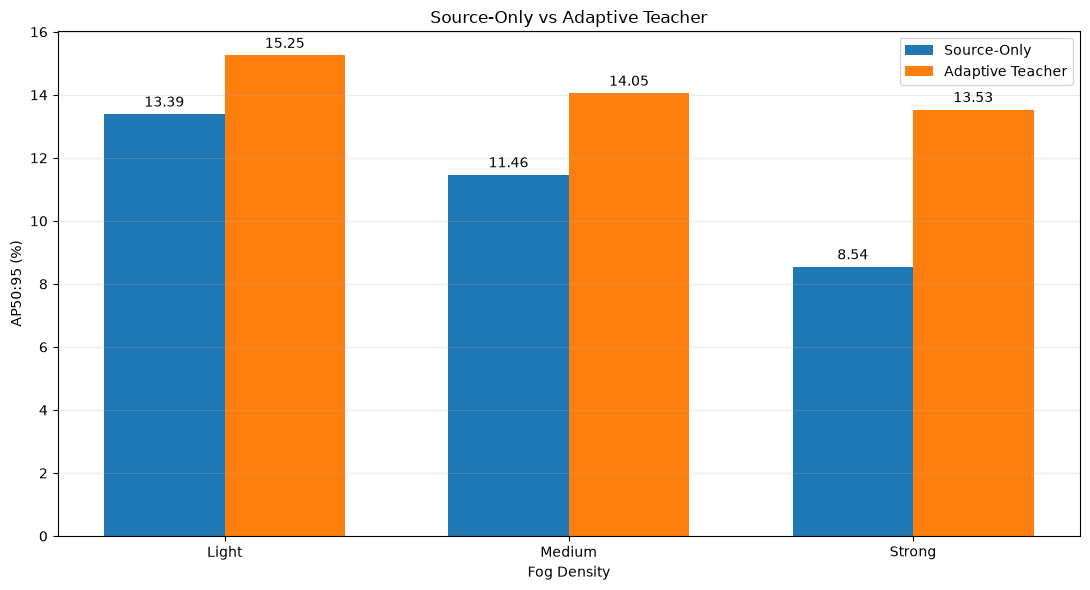

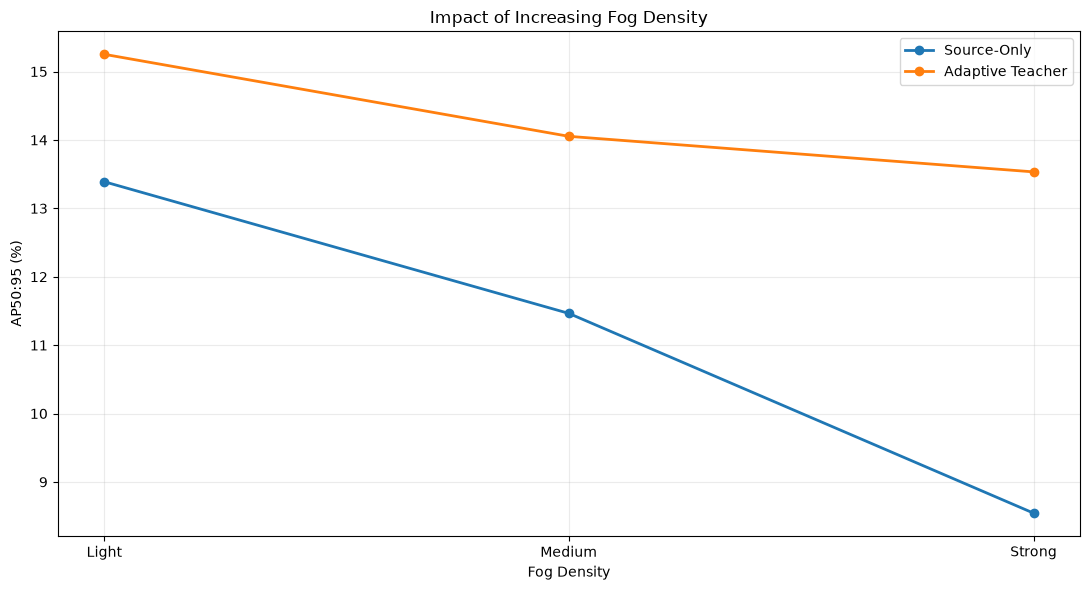

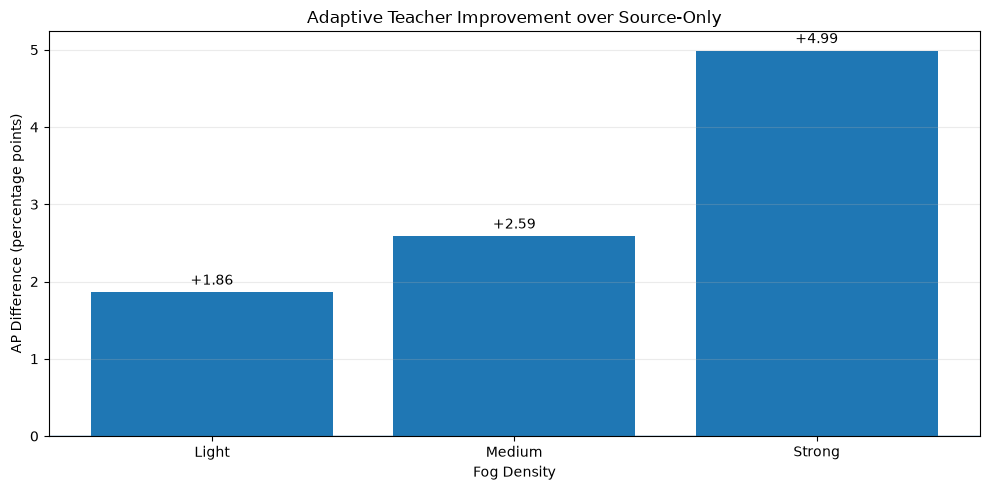

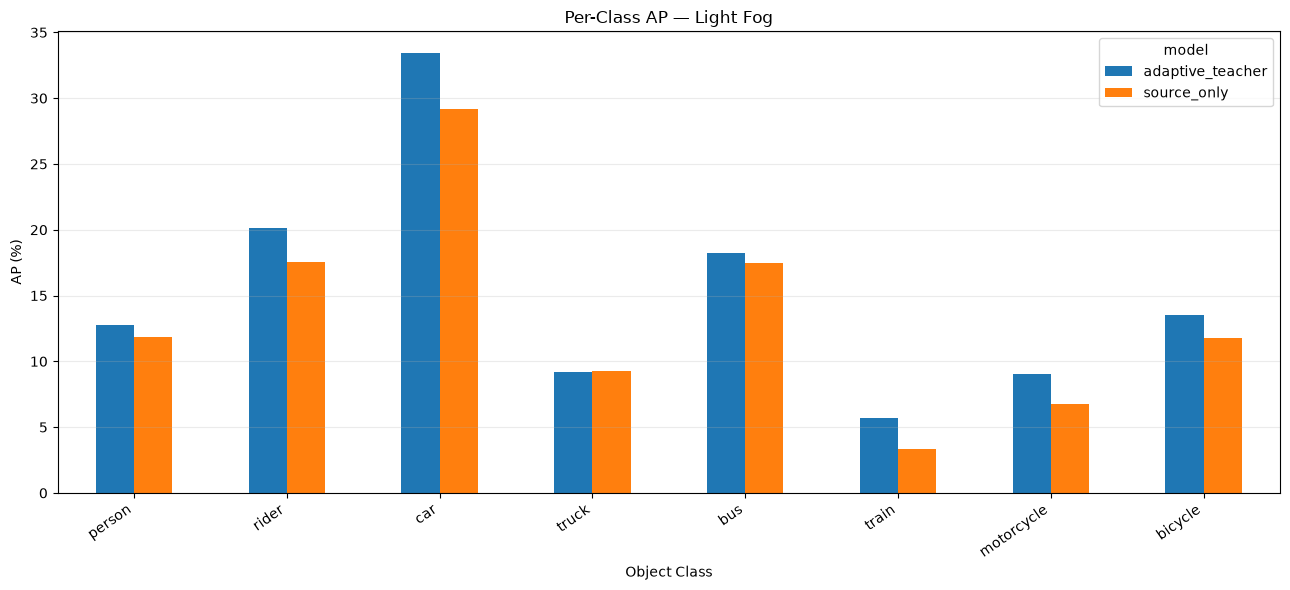

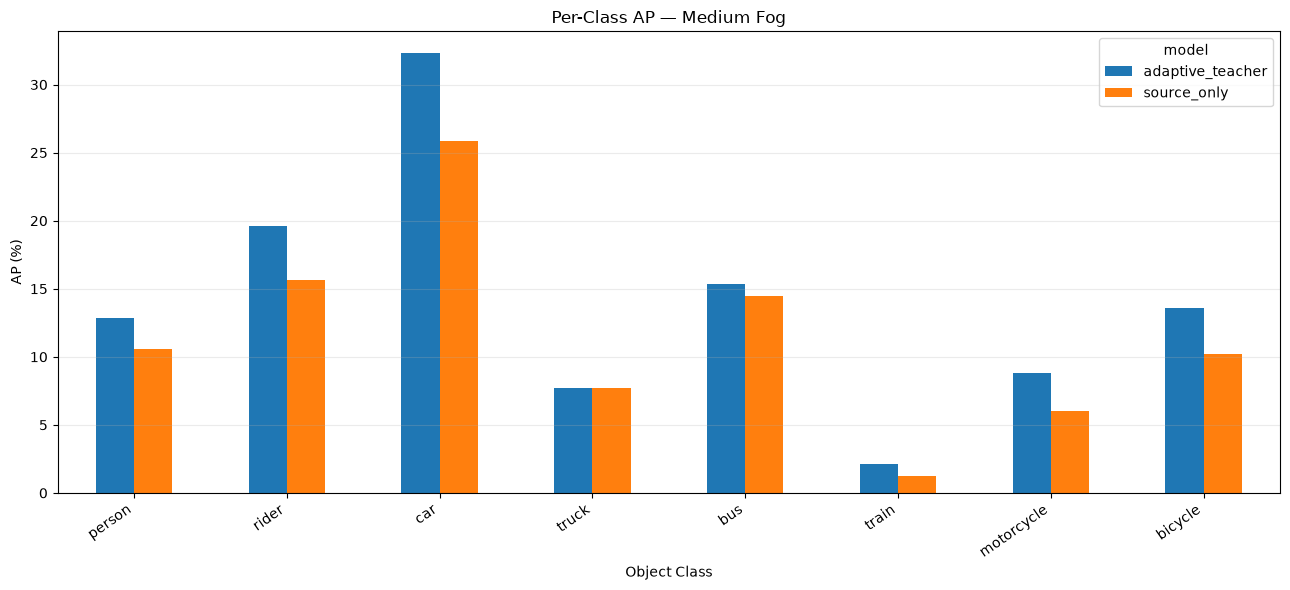

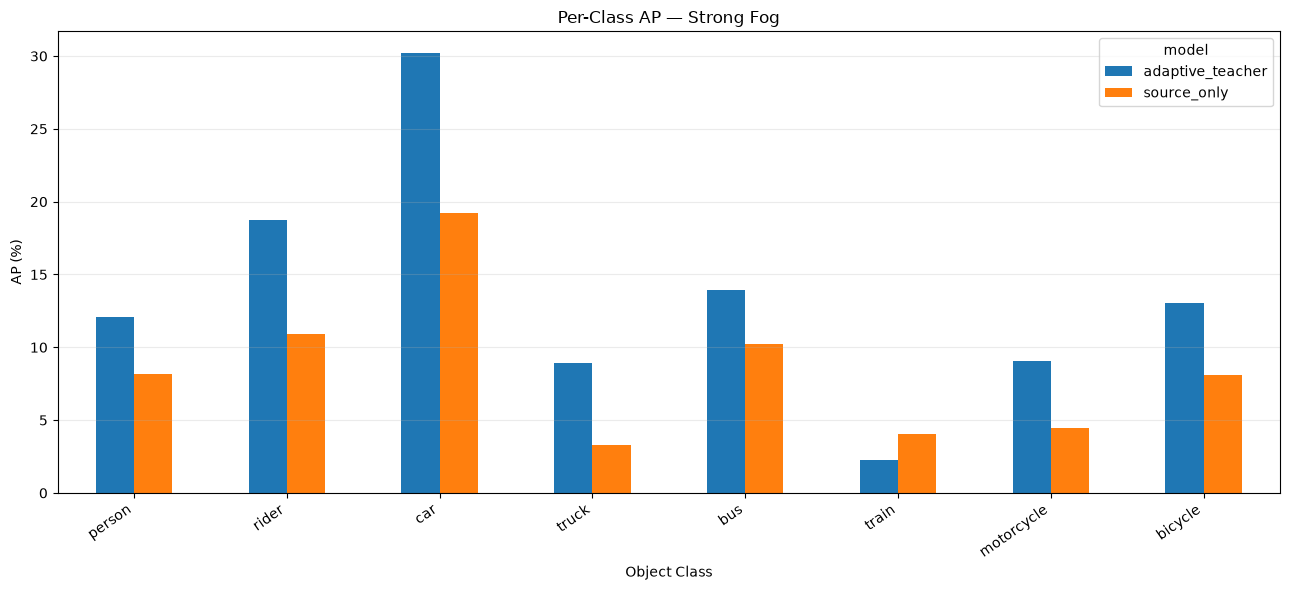


EXPERIMENT 03 COMPLETE
Results: /workspace/experiments/cityscapes_to_foggy/fog_density_evaluation/v1
Plots: /workspace/experiments/cityscapes_to_foggy/fog_density_evaluation/v1/visualizations


model,adaptive_teacher,source_only,improvement_pp
fog_density,,,
light,15.253,13.390,1.863
medium,14.053,11.464,2.589
strong,13.533,8.544,4.989


In [20]:

# =====================================================================
# EXPERIMENT 03 — RESULTS AND VISUALIZATIONS
# =====================================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "fog_density_evaluation/v1"
)

VIS_DIR = OUTPUT_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

results_df = pd.read_csv(
    OUTPUT_DIR / "fog_density_results.csv"
)

classes_df = pd.read_csv(
    OUTPUT_DIR / "per_class_results.csv"
)

ORDER = ["light", "medium", "strong"]

comparison = results_df.pivot(
    index="fog_density",
    columns="model",
    values="AP"
).reindex(ORDER)

comparison["improvement_pp"] = (
    comparison["adaptive_teacher"]
    - comparison["source_only"]
)

comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv"
)

print("=" * 65)
print("EXPERIMENT 03 — AP50:95 COMPARISON")
print("=" * 65)

display(comparison.round(3))

# ---------------------------------------------------------------------
# FIGURE 1 — SIDE-BY-SIDE MODEL COMPARISON
# ---------------------------------------------------------------------

x = np.arange(3)
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison["source_only"],
    width,
    label="Source-Only"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["adaptive_teacher"],
    width,
    label="Adaptive Teacher"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["Light", "Medium", "Strong"])
ax.set_xlabel("Fog Density")
ax.set_ylabel("AP50:95 (%)")
ax.set_title("Source-Only vs Adaptive Teacher")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    VIS_DIR / "01_model_comparison.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# FIGURE 2 — PERFORMANCE DEGRADATION
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for model, label in [
    ("source_only", "Source-Only"),
    ("adaptive_teacher", "Adaptive Teacher")
]:
    ax.plot(
        ["Light", "Medium", "Strong"],
        comparison[model],
        marker="o",
        linewidth=2,
        label=label
    )

ax.set_xlabel("Fog Density")
ax.set_ylabel("AP50:95 (%)")
ax.set_title("Impact of Increasing Fog Density")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    VIS_DIR / "02_fog_degradation.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# FIGURE 3 — ADAPTATION IMPROVEMENT
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    ["Light", "Medium", "Strong"],
    comparison["improvement_pp"]
)

ax.axhline(0, linewidth=1)
ax.bar_label(bars, fmt="%+.2f", padding=3)

ax.set_xlabel("Fog Density")
ax.set_ylabel("AP Difference (percentage points)")
ax.set_title(
    "Adaptive Teacher Improvement over Source-Only"
)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    VIS_DIR / "03_adaptation_improvement.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# FIGURE 4 — PER-CLASS AP
# ---------------------------------------------------------------------

CLASSES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
]

for level in ORDER:

    subset = classes_df[
        classes_df["fog_density"] == level
    ]

    pivot = subset.pivot(
        index="class",
        columns="model",
        values="AP"
    ).reindex(CLASSES)

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 6)
    )

    ax.set_title(
        f"Per-Class AP — {level.title()} Fog"
    )
    ax.set_xlabel("Object Class")
    ax.set_ylabel("AP (%)")
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(
        VIS_DIR / f"04_per_class_{level}.png",
        dpi=200
    )
    plt.show()

# ---------------------------------------------------------------------
# RESEARCH SUMMARY
# ---------------------------------------------------------------------

summary = {
    "experiment": "Experiment 03",
    "source": "Cityscapes",
    "target": "Foggy Cityscapes",
    "fog_levels": {
        "light": 0.005,
        "medium": 0.01,
        "strong": 0.02
    },
    "models": [
        "Source-Only",
        "Adaptive Teacher"
    ],
    "metric": "COCO AP50:95",
    "results": results_df.to_dict(orient="records"),
    "comparison": comparison.reset_index().to_dict(
        orient="records"
    )
}

with open(
    OUTPUT_DIR / "experiment_summary.json", "w"
) as f:
    json.dump(summary, f, indent=2, default=float)

print("\n" + "=" * 65)
print("EXPERIMENT 03 COMPLETE")
print("=" * 65)

print("Results:", OUTPUT_DIR)
print("Plots:", VIS_DIR)

display(comparison.round(3))
